# Figures: numerical integration and singularities

Generates, for the page *Theory → Numerical integration and singularities*:

- `numerical_integration_pairs.svg`: the four categories of triangle pairs on a real mesh, and the quadrature nodes the solver uses for each;
- `numerical_integration_convergence.svg`: why the solver treats the singular pairs specially, measured on the static kernel $1/R$.

Everything is computed with the solver's own functions (`solver.utils.quadrature`, `solver.rwg`), and the quadrature orders are read from the defaults of `impmet.impedance_matrix_z`, so the figures follow the code if those defaults change. A provenance file (`numerical_integration.json`) records the solver commit and the numbers quoted on the page.

Run it from this folder with the `antenna_solver` environment. Nothing is written to `data/`.

In [1]:
%matplotlib inline
import datetime
import inspect
import json
import tempfile
from pathlib import Path

import gmsh
import matplotlib.pyplot as plt
import numpy as np
from fontTools.ttLib import TTFont
from matplotlib import font_manager
from matplotlib.patches import Polygon

from solver.rwg.rwg1 import Points, Triangles, filter_complexes_jonctions
from solver.utils.impmet import impedance_matrix_z, NEAR_ORDER_DEFAULT
from solver.utils.quadrature.analytic_singular import inv_R_over_triangle_batch
from solver.utils.quadrature.duffy import duffy_source_nodes
from solver.utils.quadrature.gauss_dunavant import dunavant_rule, map_to_triangle
from solver.utils.quadrature.singularity_classifier import (
    classify_all_triangle_pairs, SELF, EDGE, VERTEX, FAR)

OUT_DIR = Path("../source/figures/generated")
OUT_DIR.mkdir(parents=True, exist_ok=True)

# The solver's default orders, read from the code rather than copied by hand.
defaults = {k: v.default for k, v in inspect.signature(impedance_matrix_z).parameters.items()
            if v.default is not inspect.Parameter.empty}
FAR_ORDER = defaults["quad_order"]                    # FAR pairs, both triangles
DUFFY_ORDER = defaults["duffy_order"]                 # SELF pairs, inner (source) triangle
NEAR_ORDER = max(FAR_ORDER, NEAR_ORDER_DEFAULT)      # EDGE/VERTEX pairs (impmet._default_near_order)
SELF_OUTER = FAR_ORDER                               # SELF pairs, outer (test) triangle
print(f"FAR degree {FAR_ORDER}, EDGE/VERTEX degree {NEAR_ORDER}, SELF outer degree {SELF_OUTER} + Duffy order {DUFFY_ORDER}")

# Site palette and font (the woff2 files of the website, converted to ttf in a temp folder)
BLUE, AMBER, INK, GREY = "#2563a6", "#e28a36", "#142b45", "#9aa5b1"
font_cache = Path(tempfile.gettempdir()) / "antenna_solver_docs_fonts"
font_cache.mkdir(exist_ok=True)
for variant in ("400-normal", "400-italic", "700-normal"):
    ttf = font_cache / f"iosevka-{variant}.ttf"
    if not ttf.exists():
        font = TTFont(Path("../source/_static/fonts/iosevka") / f"iosevka-latin-{variant}.woff2")
        font.flavor = None
        font.save(ttf)
    font_manager.fontManager.addfont(str(ttf))
plt.rcParams.update({
    "font.family": "Iosevka", "font.size": 11, "svg.fonttype": "path",
    "mathtext.fontset": "custom", "mathtext.rm": "Iosevka",
    "mathtext.it": "Iosevka:italic", "mathtext.bf": "Iosevka:bold",
})

FAR degree 6, EDGE/VERTEX degree 16, SELF outer degree 6 + Duffy order 7


In [2]:
# A 120 mm x 80 mm plate meshed by gmsh in memory, single-threaded (reproducible mesh).
LX, LY, H = 0.120, 0.080, 0.015

gmsh.initialize()
gmsh.option.setNumber("General.Terminal", 0)
gmsh.option.setNumber("General.NumThreads", 1)
gmsh.model.add("plate")
gmsh.model.occ.addRectangle(0, 0, 0, LX, LY)
gmsh.model.occ.synchronize()
gmsh.option.setNumber("Mesh.MeshSizeMin", H)
gmsh.option.setNumber("Mesh.MeshSizeMax", H)
gmsh.model.mesh.generate(2)
node_tags, node_coords, _ = gmsh.model.mesh.getNodes()
p = np.asarray(node_coords).reshape(-1, 3).T
index_of = {int(tag): i for i, tag in enumerate(node_tags)}
blocks = []
for dim, surface in gmsh.model.getEntities(2):
    types, _, nodes = gmsh.model.mesh.getElements(dim, surface)
    for etype, enodes in zip(types, nodes):
        if etype == 2:
            idx = np.array([index_of[int(k)] for k in enodes]).reshape(-1, 3).T
            blocks.append(np.vstack([idx, np.full((1, idx.shape[1]), surface)]))
gmsh.finalize()
t = np.hstack(blocks).astype(int)

# Same preprocessing as radiation_algorithm()
points = Points(p)
triangles = Triangles(t)
triangles.calculate_triangles_area_and_center(points)
edges = triangles.get_edges()
filter_complexes_jonctions(points, triangles, edges)
edges.compute_edges_length(points)

P, TRI = points.points, triangles.triangles[:3]
N_TRI, N_EDGES = TRI.shape[1], edges.total_number_of_edges
print(f"{N_TRI} triangles, {N_EDGES} RWG functions")

114 triangles, 157 RWG functions


In [3]:
# Category of every triangle pair (solver.utils.quadrature.singularity_classifier)
C = classify_all_triangle_pairs(TRI)

# Reference triangle: the one closest to the plate centre
t0 = int(np.argmin(np.linalg.norm(triangles.triangles_center[:2] - np.array([[LX / 2], [LY / 2]]), axis=0)))
cat_vs_t0 = C[t0]

# The triangle sub-pairs that actually enter Z: 4 per (m, n), for every m and n
tp, tm = triangles.triangles_plus, triangles.triangles_minus
sub_pairs = np.concatenate([C[a[:, None], b[None, :]].ravel() for a in (tp, tm) for b in (tp, tm)])
NAMES = {int(SELF): "SELF", int(EDGE): "EDGE", int(VERTEX): "VERTEX", int(FAR): "FAR"}
share = {NAMES[c]: float(np.mean(sub_pairs == c)) for c in (SELF, EDGE, VERTEX, FAR)}
print(f"{sub_pairs.size} triangle sub-pairs in Z ({N_EDGES}^2 x 4)")
for name, s in share.items():
    print(f"  {name:6s} {100 * s:6.2f} %")

98596 triangle sub-pairs in Z (157^2 x 4)
  SELF     0.90 %
  EDGE     2.53 %
  VERTEX   6.86 %
  FAR     89.70 %


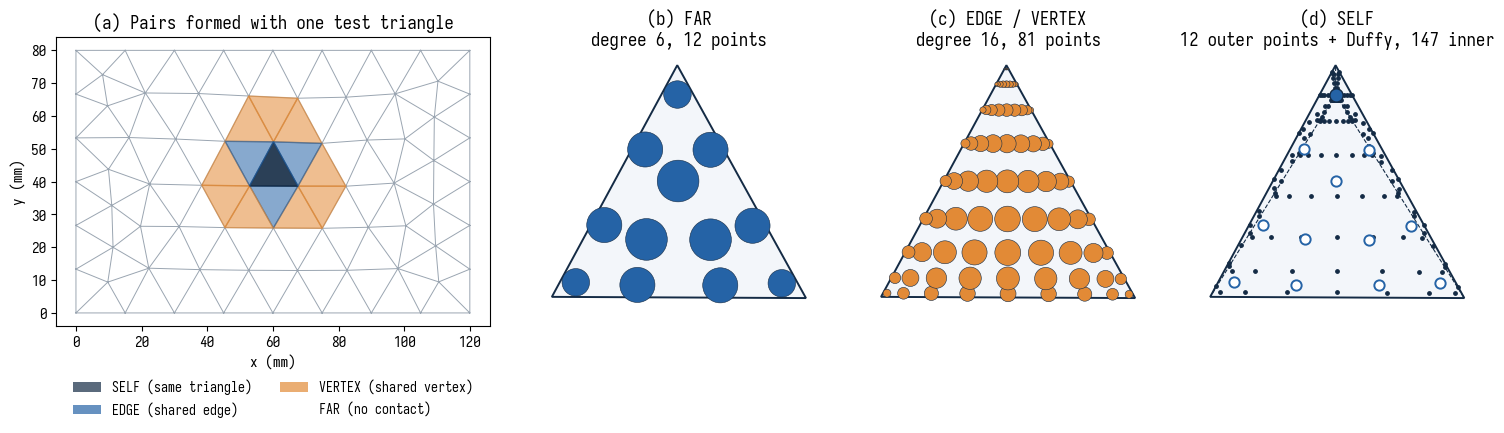

In [4]:
mm = 1e3
COLOURS = {int(SELF): INK, int(EDGE): BLUE, int(VERTEX): AMBER}

def corners(tri):
    return P[:2, TRI[:, tri]].T * mm

fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.55, 1, 1, 1]})

# (a) categories of every triangle with respect to t0
ax = axes[0]
ax.triplot(P[0] * mm, P[1] * mm, TRI.T, color=GREY, lw=0.7)
for s in range(N_TRI):
    c = int(cat_vs_t0[s])
    if c in COLOURS:
        ax.add_patch(Polygon(corners(s), closed=True, fc=COLOURS[c], ec=COLOURS[c],
                             alpha=0.9 if c == int(SELF) else 0.55))
handles = [plt.Rectangle((0, 0), 1, 1, fc=col, alpha=0.7) for col in (INK, BLUE, AMBER, "white")]
ax.legend(handles, ["SELF (same triangle)", "EDGE (shared edge)", "VERTEX (shared vertex)", "FAR (no contact)"],
          loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False, fontsize=10)
ax.set_title("(a) Pairs formed with one test triangle")
ax.set_xlabel("x (mm)")
ax.set_ylabel("y (mm)")

# (b)-(d) nodes on the test triangle itself, in mm around its centroid
V0 = P[:, TRI[:, t0]]
c0 = V0.mean(axis=1, keepdims=True)

def local(r):
    return (r - c0)[:2] * mm

def draw_triangle(ax):
    xy = local(V0).T
    ax.add_patch(Polygon(xy, closed=True, fc="#f3f6fa", ec=INK, lw=1.4))

def rule_nodes(degree):
    xi, w = dunavant_rule(degree)
    return map_to_triangle(xi, V0[:, 0], V0[:, 1], V0[:, 2]), w

for ax, degree, col, title in ((axes[1], FAR_ORDER, BLUE, "(b) FAR"), (axes[2], NEAR_ORDER, AMBER, "(c) EDGE / VERTEX")):
    draw_triangle(ax)
    r, w = rule_nodes(degree)
    ax.scatter(*local(r), s=900 * w / w.max() * (12 / len(w)) ** 0.5, color=col, edgecolor=INK, lw=0.4, zorder=3)
    ax.set_title(f"{title}\ndegree {degree}, {len(w)} points")

ax = axes[3]
draw_triangle(ax)
r_out, w_out = rule_nodes(SELF_OUTER)
p_star = int(np.argmax(np.linalg.norm(r_out - c0, axis=0)))       # an outer node near a corner
r_star = r_out[:, p_star]
d_pts, d_w = duffy_source_nodes(r_star, V0[:, 0], V0[:, 1], V0[:, 2], order=DUFFY_ORDER)
for k in range(3):                                                  # the three Duffy sub-triangles
    ax.plot(*local(np.column_stack([r_star, V0[:, k]])), color=INK, lw=0.8, ls="--")
ax.scatter(*local(d_pts.T), s=6, color=INK, zorder=3)
ax.scatter(*local(r_out), s=55, facecolor="white", edgecolor=BLUE, lw=1.4, zorder=4)
ax.scatter(*local(r_star[:, None]), s=90, color=BLUE, edgecolor=INK, zorder=5)
ax.set_title(f"(d) SELF\n{len(w_out)} outer points + Duffy, {len(d_w)} inner")

for ax in axes[1:]:
    ax.set_xticks([]); ax.set_yticks([])
    for side in ax.spines.values():
        side.set_visible(False)
for ax in axes:
    ax.set_aspect("equal")

fig.tight_layout()
fig.savefig(OUT_DIR / "numerical_integration_pairs.svg", bbox_inches="tight", facecolor="white")
plt.show()

## Convergence on the singular kernel

The quantity is the static double integral $I = \int_{T_t}\int_{T_s} \frac{dS'\,dS}{|\mathbf r-\mathbf r'|}$, the part of the scalar-potential kernel that the solver treats specially. It is computed for an EDGE pair (two triangles sharing an edge) and a SELF pair (a triangle with itself) taken from the mesh above.

**Reference.** The test triangle is split into $4^4 = 256$ sub-triangles with a degree-16 rule on each, and the inner integral is taken in closed form (`inv_R_over_triangle_batch`). The same reference with $4^3$ sub-triangles is computed as a check of its own accuracy.

In [5]:
DEGREES = [1, 3, 4, 5, 6, 7, 11, 16, 20, 24]

def vertices(tri):
    return P[:, TRI[:, tri]]

def outer_rule(V, degree):
    """Physical nodes and weights: int_T f dS ~ sum_q w_q f(r_q)."""
    xi, w = dunavant_rule(degree)
    area = 0.5 * np.linalg.norm(np.cross(V[:, 1] - V[:, 0], V[:, 2] - V[:, 0]))
    return map_to_triangle(xi, V[:, 0], V[:, 1], V[:, 2]), 2 * area * w

def inner_closed_form(r, Vs):
    n = r.shape[1]
    return inv_R_over_triangle_batch(r, *(np.repeat(Vs[:, i:i + 1], n, axis=1) for i in range(3)))

def subdivide(V, levels):
    tris = [V]
    for _ in range(levels):
        new = []
        for T in tris:
            a, b, c = T.T
            ab, bc, ca = (a + b) / 2, (b + c) / 2, (c + a) / 2
            new += [np.column_stack(x) for x in ((a, ab, ca), (ab, b, bc), (ca, bc, c), (ab, bc, ca))]
        tris = new
    return tris

def reference(Vt, Vs, levels):
    return sum(w @ inner_closed_form(r, Vs) for r, w in (outer_rule(T, 16) for T in subdivide(Vt, levels)))

def plain_gauss(Vt, Vs, degree):
    """Same rule on both triangles (the FAR scheme)."""
    r_t, w_t = outer_rule(Vt, degree)
    r_s, w_s = outer_rule(Vs, degree)
    R = np.linalg.norm(r_t[:, :, None] - r_s[:, None, :], axis=0)
    return w_t @ (1.0 / R) @ w_s

def closed_form_inner(Vt, Vs, degree):
    """Gauss on the test triangle, 1/R in closed form on the source (the EDGE/VERTEX scheme)."""
    r, w = outer_rule(Vt, degree)
    return w @ inner_closed_form(r, Vs)

def duffy_inner(Vt, Vs, degree, order):
    """Gauss on the test triangle, Duffy on the source around each node (the SELF scheme)."""
    r, w = outer_rule(Vt, degree)
    inner = []
    for q in range(r.shape[1]):
        d_pts, d_w = duffy_source_nodes(r[:, q], Vs[:, 0], Vs[:, 1], Vs[:, 2], order=order)
        inner.append(d_w @ (1.0 / np.linalg.norm(d_pts - r[:, q], axis=1)))
    return w @ np.array(inner)

# The pairs: t0 with itself (SELF) and with one of its edge neighbours (EDGE)
t_edge = int(np.flatnonzero(C[t0] == EDGE)[0])
Vt, V_edge = vertices(t0), vertices(t_edge)

ref = {}
for name, Vs in (("EDGE", V_edge), ("SELF", Vt)):
    fine, coarse = reference(Vt, Vs, 4), reference(Vt, Vs, 3)
    ref[name] = fine
    print(f"{name}: reference I = {fine:.12e}  (4^3 vs 4^4 sub-triangles: rel. diff {abs(coarse - fine) / fine:.1e})")

def rel(x, name):
    return abs(x - ref[name]) / abs(ref[name])

err = {
    "EDGE, Gauss on both": [rel(plain_gauss(Vt, V_edge, d), "EDGE") for d in DEGREES],
    "EDGE, closed-form inner": [rel(closed_form_inner(Vt, V_edge, d), "EDGE") for d in DEGREES],
    "SELF, Duffy inner": [rel(duffy_inner(Vt, Vt, d, DUFFY_ORDER), "SELF") for d in DEGREES],
    "SELF, closed-form inner": [rel(closed_form_inner(Vt, Vt, d), "SELF") for d in DEGREES],
}
print(f"\n{'degree':>6s} " + " ".join(f"{k:>24s}" for k in err))
for i, d in enumerate(DEGREES):
    print(f"{d:6d} " + " ".join(f"{err[k][i]:24.2e}" for k in err))

EDGE: reference I = 1.165345374694e-06  (4^3 vs 4^4 sub-triangles: rel. diff 1.7e-06)


SELF: reference I = 2.858173546768e-06  (4^3 vs 4^4 sub-triangles: rel. diff 1.1e-06)

degree      EDGE, Gauss on both  EDGE, closed-form inner        SELF, Duffy inner  SELF, closed-form inner
     1                 8.28e-02                 6.98e-02                 1.99e-01                 1.99e-01
     3                 1.41e-02                 1.78e-02                 3.01e-02                 2.81e-02
     4                 4.16e-03                 7.03e-03                 1.65e-02                 8.68e-03
     5                 1.73e-02                 3.80e-03                 1.58e-02                 5.32e-03
     6                 1.20e-02                 1.95e-03                 3.56e-03                 2.47e-03
     7                 8.20e-03                 1.30e-03                 2.93e-03                 8.81e-04
    11                 6.13e-03                 3.71e-04                 1.17e-02                 2.49e-04
    16                 4.42e-03                 1.43e-04 

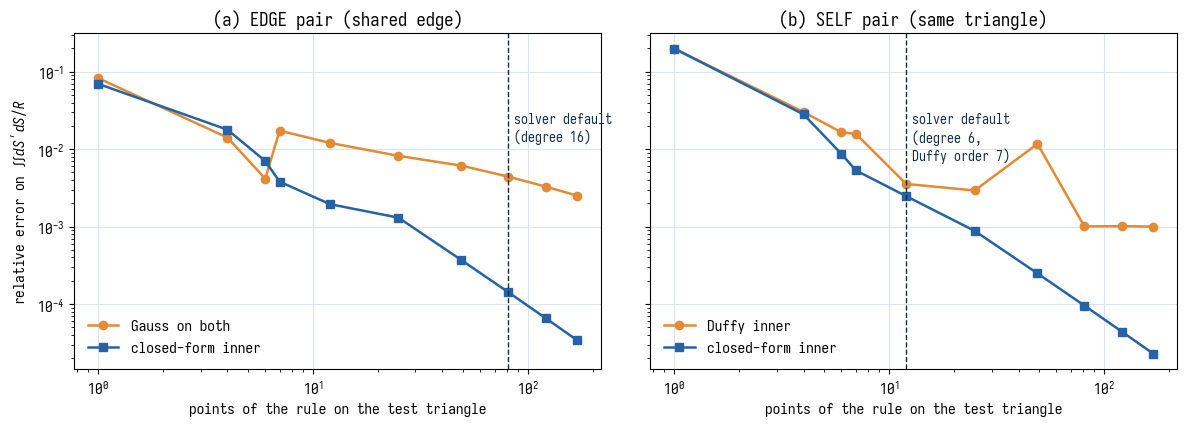

In [6]:
fig, (ax_e, ax_s) = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
n_points = [len(dunavant_rule(d)[1]) for d in DEGREES]

def panel(ax, curves, default_degree, default_label, title):
    for label, col, marker in curves:
        ax.loglog(n_points, np.maximum(err[label], 1e-17), marker=marker, color=col, lw=1.8, ms=6, label=label.split(", ")[1])
    x_def = len(dunavant_rule(default_degree)[1])
    ax.axvline(x_def, color=INK, ls="--", lw=1)
    ax.text(x_def * 1.06, 3e-2, default_label, color=INK, fontsize=10, va="top")
    ax.set_title(title)
    ax.set_xlabel("points of the rule on the test triangle")
    ax.grid(True, which="major", color="#dde3ea", lw=0.8)
    ax.legend(frameon=False, loc="lower left")

panel(ax_e, [("EDGE, Gauss on both", AMBER, "o"), ("EDGE, closed-form inner", BLUE, "s")],
      NEAR_ORDER, f"solver default\n(degree {NEAR_ORDER})", "(a) EDGE pair (shared edge)")
panel(ax_s, [("SELF, Duffy inner", AMBER, "o"), ("SELF, closed-form inner", BLUE, "s")],
      SELF_OUTER, f"solver default\n(degree {SELF_OUTER},\nDuffy order {DUFFY_ORDER})", "(b) SELF pair (same triangle)")
ax_e.set_ylabel(r"relative error on $\int\!\!\int dS'\,dS/R$")

fig.tight_layout()
fig.savefig(OUT_DIR / "numerical_integration_convergence.svg", bbox_inches="tight", facecolor="white")
plt.show()

In [7]:
def git_commit(repo=Path("../..")):
    """Current commit, read from .git directly (git may not be on the kernel's PATH)."""
    git_dir = repo / ".git"
    head = (git_dir / "HEAD").read_text().strip()
    if not head.startswith("ref: "):
        return head[:7]
    ref_file = git_dir / head[5:]
    if ref_file.exists():
        return ref_file.read_text().strip()[:7]
    for line in (git_dir / "packed-refs").read_text().splitlines():
        if line.endswith(" " + head[5:]):
            return line.split()[0][:7]
    return "unknown"

def at(label, degree):
    return err[label][DEGREES.index(degree)]

provenance = {
    "figures": ["numerical_integration_pairs.svg", "numerical_integration_convergence.svg"],
    "notebook": "documentation/figure_notebooks/theory_numerical_integration.ipynb",
    "solver_commit": git_commit(),
    "generated": datetime.date.today().isoformat(),
    "solver_defaults": {"far_degree": FAR_ORDER, "near_degree": NEAR_ORDER,
                        "self_outer_degree": SELF_OUTER, "duffy_order": DUFFY_ORDER},
    "mesh": {"plate_m": [LX, LY], "element_size_m": H, "triangles": N_TRI, "rwg_functions": N_EDGES},
    "share_of_sub_pairs_in_Z": share,
    "relative_error_static_kernel": {
        "degrees": DEGREES, **err,
        "EDGE_gauss_both_at_near_default": at("EDGE, Gauss on both", NEAR_ORDER),
        "EDGE_closed_form_at_near_default": at("EDGE, closed-form inner", NEAR_ORDER),
        "SELF_duffy_at_self_default": at("SELF, Duffy inner", SELF_OUTER),
        "SELF_closed_form_at_self_default": at("SELF, closed-form inner", SELF_OUTER),
    },
}
(OUT_DIR / "numerical_integration.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
print(json.dumps({k: provenance[k] for k in ("solver_commit", "solver_defaults", "share_of_sub_pairs_in_Z")}, indent=2))
print(json.dumps({k: v for k, v in provenance["relative_error_static_kernel"].items() if "default" in k}, indent=2))

{
  "solver_commit": "1b6a6e2",
  "solver_defaults": {
    "far_degree": 6,
    "near_degree": 16,
    "self_outer_degree": 6,
    "duffy_order": 7
  },
  "share_of_sub_pairs_in_Z": {
    "SELF": 0.00898616576737393,
    "EDGE": 0.025335713416365774,
    "VERTEX": 0.06864375836747941,
    "FAR": 0.8970343624487809
  }
}
{
  "EDGE_gauss_both_at_near_default": 0.004422607873539533,
  "EDGE_closed_form_at_near_default": 0.00014266901289110482,
  "SELF_duffy_at_self_default": 0.0035582041406975445,
  "SELF_closed_form_at_self_default": 0.002474714877667426
}
